Saving sales_data.csv to sales_data.csv
Rows loaded: 100
        Date     Product  Quantity  Price Customer_ID Region  Total_Sales  \
0 2024-01-01       Phone         7  37300     CUST001   East       261100   
1 2024-01-02  Headphones         4  15406     CUST002  North        61624   
2 2024-01-03       Phone         2  21746     CUST003   West        43492   
3 2024-01-04  Headphones         1  30895     CUST004   East        30895   
4 2024-01-05      Laptop         8  39835     CUST005  North       318680   

   Month MonthName  
0      1       Jan  
1      1       Jan  
2      1       Jan  
3      1       Jan  
4      1       Jan  


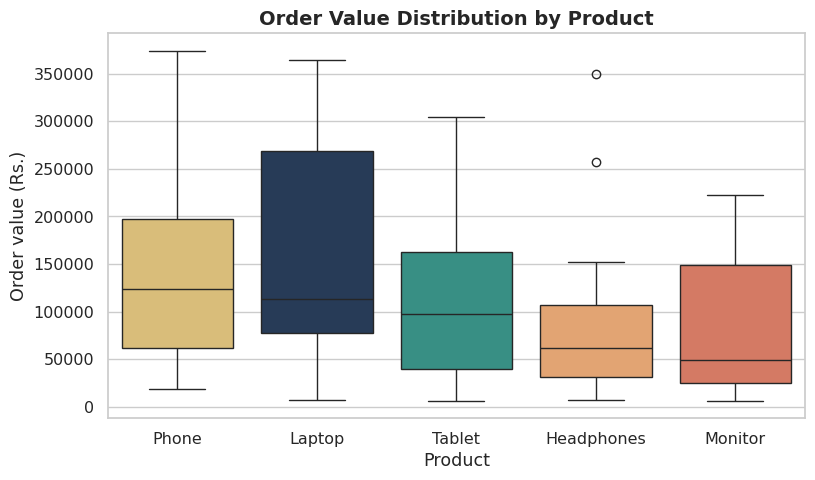

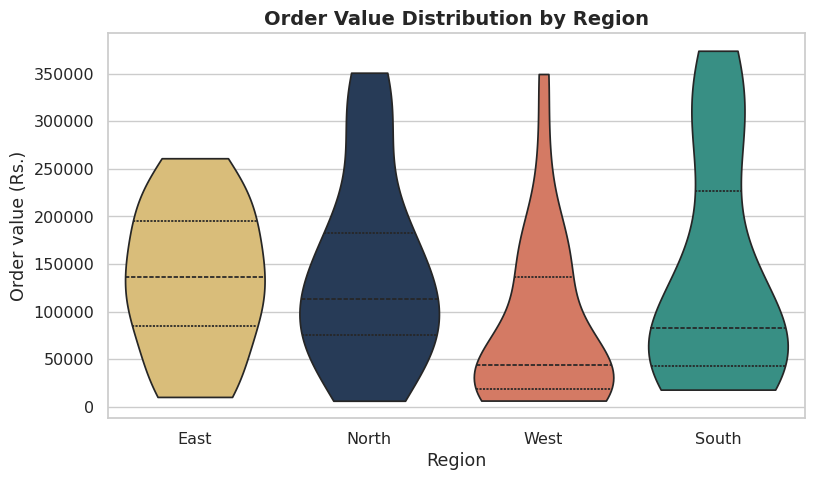

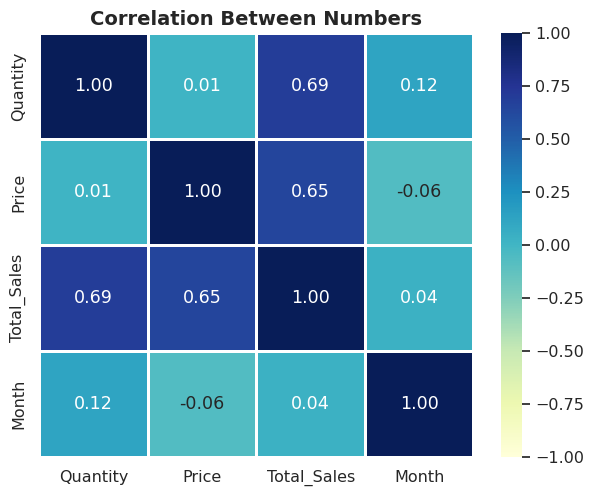

In [1]:
# Week 6 - Interactive Sales Dashboard
# Step 1: Load the data, set one colour theme, and make 3 Seaborn charts

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

REQUIRED_COLUMNS = ['Date', 'Product', 'Quantity', 'Price', 'Customer_ID', 'Region', 'Total_Sales']


def load_data(path):
    """Load the CSV file. Return None and print a message if something is wrong."""
    try:
        df = pd.read_csv(path)
    except FileNotFoundError:
        print(f"Error: file '{path}' was not found.")
        return None
    except Exception as error:
        print("Error while reading the file:", error)
        return None
    missing = [c for c in REQUIRED_COLUMNS if c not in df.columns]
    if missing:
        print("Error: these columns are missing:", missing)
        return None
    df = df.dropna().drop_duplicates()
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    df = df.dropna(subset=['Date'])
    df['Month'] = df['Date'].dt.month
    df['MonthName'] = df['Date'].dt.strftime('%b')
    return df


PRODUCT_COLORS = {'Laptop': '#1f3a5f', 'Tablet': '#2a9d8f', 'Phone': '#e9c46a',
                  'Headphones': '#f4a261', 'Monitor': '#e76f51'}
REGION_COLORS = {'North': '#1f3a5f', 'South': '#2a9d8f', 'East': '#e9c46a', 'West': '#e76f51'}
sns.set_theme(style='whitegrid', font_scale=1.05)

os.makedirs('visualizations', exist_ok=True)

from google.colab import files
uploaded = files.upload()
df = load_data(list(uploaded.keys())[0])

if df is not None:
    print("Rows loaded:", len(df))
    print(df.head())

    order = df.groupby('Product')['Total_Sales'].median().sort_values(ascending=False).index
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df, x='Product', y='Total_Sales', hue='Product',
                order=order, palette=PRODUCT_COLORS, legend=False)
    plt.title('Order Value Distribution by Product', fontsize=14, fontweight='bold')
    plt.ylabel('Order value (Rs.)')
    plt.savefig('visualizations/1_boxplot_product.png', dpi=150, bbox_inches='tight')
    plt.show()

    plt.figure(figsize=(9, 5))
    sns.violinplot(data=df, x='Region', y='Total_Sales', hue='Region',
                   palette=REGION_COLORS, inner='quartile', legend=False, cut=0)
    plt.title('Order Value Distribution by Region', fontsize=14, fontweight='bold')
    plt.ylabel('Order value (Rs.)')
    plt.savefig('visualizations/2_violin_region.png', dpi=150, bbox_inches='tight')
    plt.show()

    corr = df[['Quantity', 'Price', 'Total_Sales', 'Month']].corr()
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='YlGnBu', vmin=-1, vmax=1,
                linewidths=1, linecolor='white')
    plt.title('Correlation Between Numbers', fontsize=14, fontweight='bold')
    plt.savefig('visualizations/3_correlation_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()

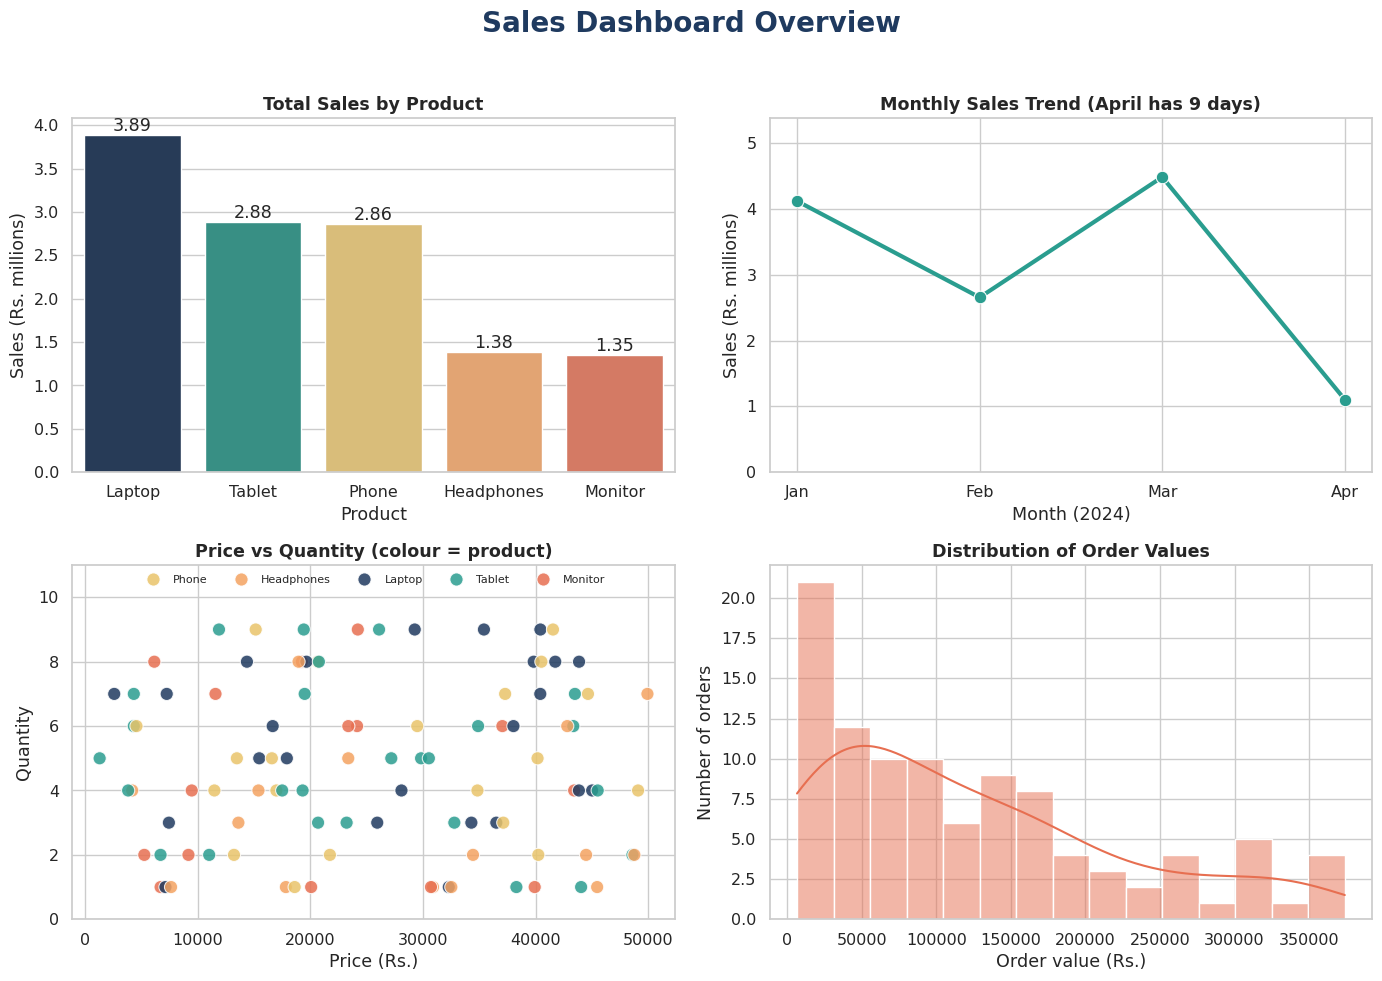

In [2]:
# Step 2: A 2x2 dashboard grid (4 more Seaborn chart types)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Sales Dashboard Overview', fontsize=20, fontweight='bold', color='#1f3a5f')

# ----- Top left: Bar chart - total sales by product -----
by_product = df.groupby('Product')['Total_Sales'].sum().sort_values(ascending=False).reset_index()
by_product['Sales_M'] = by_product['Total_Sales'] / 1_000_000
sns.barplot(data=by_product, x='Product', y='Sales_M', hue='Product',
            palette=PRODUCT_COLORS, legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Total Sales by Product', fontweight='bold')
axes[0, 0].set_ylabel('Sales (Rs. millions)')
for bar in axes[0, 0].patches:
    axes[0, 0].annotate(f"{bar.get_height():.2f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        ha='center', va='bottom')

# ----- Top right: Line chart - monthly sales trend -----
monthly = df.groupby(['Month', 'MonthName'])['Total_Sales'].sum().reset_index()
monthly['Sales_M'] = monthly['Total_Sales'] / 1_000_000
sns.lineplot(data=monthly, x='Month', y='Sales_M', marker='o', markersize=9,
             linewidth=3, color='#2a9d8f', ax=axes[0, 1])
axes[0, 1].set_xticks(monthly['Month'])
axes[0, 1].set_xticklabels(monthly['MonthName'])
axes[0, 1].set_title('Monthly Sales Trend (April has 9 days)', fontweight='bold')
axes[0, 1].set_xlabel('Month (2024)')
axes[0, 1].set_ylabel('Sales (Rs. millions)')
axes[0, 1].set_ylim(0, monthly['Sales_M'].max() * 1.2)

# ----- Bottom left: Scatter plot - price against quantity -----
sns.scatterplot(data=df, x='Price', y='Quantity', hue='Product', palette=PRODUCT_COLORS,
                s=90, alpha=0.85, ax=axes[1, 0])
axes[1, 0].set_title('Price vs Quantity (colour = product)', fontweight='bold')
axes[1, 0].set_xlabel('Price (Rs.)')
axes[1, 0].set_ylim(0, 11)
axes[1, 0].legend(ncol=5, fontsize=8, loc='upper center', frameon=False)

# ----- Bottom right: Histogram - how big are the orders? -----
sns.histplot(df['Total_Sales'], bins=15, kde=True, color='#e76f51', ax=axes[1, 1])
axes[1, 1].set_title('Distribution of Order Values', fontweight='bold')
axes[1, 1].set_xlabel('Order value (Rs.)')
axes[1, 1].set_ylabel('Number of orders')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('visualizations/4_dashboard_grid.png', dpi=150, bbox_inches='tight')
plt.show()

In [3]:
# Step 3: Interactive charts with Plotly (hover, dropdown menus and animation)

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

PRODUCTS = list(PRODUCT_COLORS.keys())
MONTH_ORDER = ['Jan', 'Feb', 'Mar', 'Apr']
NAVY = '#1f3a5f'

# ---------- Prepare the numbers ----------
prod = df.groupby('Product').agg(Total_Sales=('Total_Sales', 'sum'),
                                 Units_Sold=('Quantity', 'sum'),
                                 Average_Order=('Total_Sales', 'mean'),
                                 Orders=('Total_Sales', 'count')).reindex(
                                 df.groupby('Product')['Total_Sales'].sum().sort_values(ascending=False).index).reset_index()

# ---------- Interactive chart 1: bar chart with HOVER and a DROPDOWN (choose what to show) ----------
metrics = {'Total Sales (Rs.)': 'Total_Sales', 'Units Sold': 'Units_Sold',
           'Average Order (Rs.)': 'Average_Order', 'Number of Orders': 'Orders'}
fig1 = go.Figure(go.Bar(x=prod['Product'], y=prod['Total_Sales'],
                        marker_color=[PRODUCT_COLORS[p] for p in prod['Product']],
                        customdata=prod[['Units_Sold', 'Orders']],
                        hovertemplate='<b>%{x}</b><br>Value: %{y:,.0f}<br>Units sold: %{customdata[0]}<br>Orders: %{customdata[1]}<extra></extra>'))
fig1.update_layout(
    title='Product Performance (use the dropdown to change the measure)',
    template='plotly_white', height=500, yaxis_title='Total Sales (Rs.)',
    updatemenus=[dict(type='dropdown', x=0.0, y=1.18, xanchor='left',
                      buttons=[dict(label=label, method='update',
                                    args=[{'y': [prod[col]]}, {'yaxis.title.text': label}])
                               for label, col in metrics.items()])])
fig1.write_html('visualizations/5_interactive_bar_dropdown.html', include_plotlyjs='cdn')
fig1.show()

# ---------- Interactive chart 2: line chart with a REGION dropdown ----------
reg_month = df.groupby(['Month', 'MonthName', 'Region'])['Total_Sales'].sum().reset_index()
all_month = df.groupby(['Month', 'MonthName'])['Total_Sales'].sum().reset_index()
regions = ['North', 'South', 'East', 'West']

fig2 = go.Figure()
fig2.add_trace(go.Scatter(x=all_month['MonthName'], y=all_month['Total_Sales'], name='All regions',
                          mode='lines+markers', line=dict(color=NAVY, width=4),
                          hovertemplate='%{x}: Rs.%{y:,.0f}<extra>All regions</extra>'))
for r in regions:
    d = reg_month[reg_month['Region'] == r]
    fig2.add_trace(go.Scatter(x=d['MonthName'], y=d['Total_Sales'], name=r, mode='lines+markers',
                              line=dict(color=REGION_COLORS[r], width=4), visible=False,
                              hovertemplate='%{x}: Rs.%{y:,.0f}<extra>' + r + '</extra>'))
names = ['All regions'] + regions
buttons = [dict(label=n, method='update',
                args=[{'visible': [n == m for m in names]}, {'title': f'Monthly Sales: {n}'}])
           for n in names]
fig2.update_layout(title='Monthly Sales: All regions (use the dropdown to pick a region)',
                   template='plotly_white', height=500, yaxis_title='Sales (Rs.)',
                   xaxis=dict(categoryorder='array', categoryarray=MONTH_ORDER),
                   updatemenus=[dict(type='dropdown', x=0.0, y=1.18, xanchor='left', buttons=buttons)])
fig2.write_html('visualizations/6_interactive_line_dropdown.html', include_plotlyjs='cdn')
fig2.show()

# ---------- Interactive chart 3: ANIMATED bar chart (press Play to see each month) ----------
wide = df.pivot_table(index=['Month', 'MonthName'], columns='Product', values='Total_Sales',
                      aggfunc='sum', fill_value=0).reset_index()
anim = wide.melt(id_vars=['Month', 'MonthName'], var_name='Product', value_name='Sales').sort_values('Month')
fig3 = px.bar(anim, x='Product', y='Sales', color='Product', animation_frame='MonthName',
              color_discrete_map=PRODUCT_COLORS, range_y=[0, anim['Sales'].max() * 1.15],
              category_orders={'MonthName': MONTH_ORDER, 'Product': PRODUCTS},
              title='Sales by Product, Month by Month (press Play)')
fig3.update_layout(template='plotly_white', height=520, yaxis_title='Sales (Rs.)', showlegend=False)
fig3.write_html('visualizations/7_animated_sales_by_month.html', include_plotlyjs='cdn')
fig3.show()

# ---------- The full interactive dashboard (4 panels, one colour scheme) ----------
dash = make_subplots(rows=2, cols=2,
                     specs=[[{}, {}], [{'type': 'domain'}, {}]],
                     subplot_titles=('Total Sales by Product', 'Monthly Sales Trend',
                                     'Share of Sales by Region', 'Price vs Quantity (hover for customer)'))
dash.add_trace(go.Bar(x=prod['Product'], y=prod['Total_Sales'], showlegend=False,
                      marker_color=[PRODUCT_COLORS[p] for p in prod['Product']],
                      hovertemplate='<b>%{x}</b><br>Rs.%{y:,.0f}<extra></extra>'), row=1, col=1)
dash.add_trace(go.Scatter(x=all_month['MonthName'], y=all_month['Total_Sales'], showlegend=False,
                          mode='lines+markers', line=dict(color='#2a9d8f', width=4),
                          hovertemplate='%{x}: Rs.%{y:,.0f}<extra></extra>'), row=1, col=2)
by_region = df.groupby('Region')['Total_Sales'].sum().reindex(regions)
dash.add_trace(go.Pie(labels=by_region.index, values=by_region.values, hole=0.45,
                      marker=dict(colors=[REGION_COLORS[r] for r in by_region.index]),
                      hovertemplate='<b>%{label}</b><br>Rs.%{value:,.0f} (%{percent})<extra></extra>'),
               row=2, col=1)
for p in PRODUCTS:
    d = df[df['Product'] == p]
    dash.add_trace(go.Scatter(x=d['Price'], y=d['Quantity'], mode='markers', name=p,
                              marker=dict(color=PRODUCT_COLORS[p], size=10, opacity=0.85),
                              customdata=d[['Customer_ID', 'Total_Sales']],
                              hovertemplate='<b>%{customdata[0]}</b><br>Price: Rs.%{x:,.0f}<br>Quantity: %{y}<br>Order: Rs.%{customdata[1]:,.0f}<extra>' + p + '</extra>'),
                   row=2, col=2)
dash.update_xaxes(categoryorder='array', categoryarray=MONTH_ORDER, row=1, col=2)
dash.update_xaxes(title_text='Price (Rs.)', row=2, col=2)
dash.update_yaxes(title_text='Sales (Rs.)', row=1, col=1)
dash.update_yaxes(title_text='Sales (Rs.)', row=1, col=2)
dash.update_yaxes(title_text='Quantity', row=2, col=2)
dash.update_layout(title=dict(text='Interactive Sales Dashboard', font=dict(size=24, color=NAVY)),
                   template='plotly_white', height=800, legend=dict(title='Product'))
dash.write_html('visualizations/8_interactive_dashboard.html', include_plotlyjs='cdn')
dash.show()

In [4]:

# Put the dashboard files in one zip file and download it
import shutil
from google.colab import files

shutil.make_archive('week6_visualizations', 'zip', 'visualizations')
files.download('week6_visualizations.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>